# Qwen3-4B on Spider dev: RAG and ReAct ablation

This notebook reruns the whole experiment end to end: the baseline run plus the five extension arms, then the comparison tables and sampled traces. Every step calls the scripts in `agent_ext/`, so results match runs made from the command line.

**Arms.** Each arm is one full run of Qwen3-4B (bf16, greedy decoding, thinking off, batch size 64) over the 1034 Spider dev questions. A ✓ means that component is on.

| arm | few-shot (5 nearest train examples) | ReAct loop | act tools |
|---|---|---|---|
| `base` | – | – | – (the original A1 prompt) |
| `rag` | ✓ | – | – |
| `react` | – | ✓ | `execute` |
| `react_parse` | – | ✓ | `execute` + `spider_parse` |
| `rag_react` | ✓ | ✓ | `execute` |
| `rag_react_parse` | ✓ | ✓ | `execute` + `spider_parse` |

Compare two arms that differ in one column to see the effect of that component. For example, `rag` vs `base` is the effect of RAG, and `rag_react` vs `rag` is what ReAct adds on top of RAG.

- `execute` runs the query on a schema-only SQLite database, which has no rows. It reports the result columns or the SQLite error.
- `spider_parse` reports whether Spider's grader can parse the query.
- Few-shot examples come from Spider **train**, which shares no databases with dev.

## 0. One-time setup (login node, needs internet)

Run this from the repo root on a machine with internet access. It creates `.venv`, the schema-only Spider databases, NLTK data, and the model weights (Qwen3-4B and the all-MiniLM-L6-v2 embedder). It also installs `ipykernel` so you can select `.venv` as this notebook's kernel:

```bash
bash setup_env.sh
source .venv/bin/activate && python -m ipykernel install --user --name cisc451 --display-name "CISC451 (.venv)"
```

## 0. One-time setup (login node, needs internet)

Run this from the repo root on a machine with internet access. It creates `.venv`, the schema-only Spider databases, NLTK data, and the model weights (Qwen3-4B and the all-MiniLM-L6-v2 embedder). It also installs `ipykernel` so you can select `.venv` as this notebook's kernel:

```bash
bash setup_env.sh
source .venv/bin/activate && python -m ipykernel install --user --name cisc451 --display-name "CISC451 (.venv)"
```

Then open this notebook with the **CISC451 (.venv)** kernel. The setup script skips steps that are already done, so it's safe to rerun.

See `README.md` for the full repo setup and for running each step from the command line.

## 1. Configuration

In [1]:
import contextlib, io, os, subprocess, sys, time
from IPython.display import Markdown, display

# run from the repo root; importing agent_ext puts a1_lib and spider on sys.path and sets NLTK_DATA
sys.path.insert(0, os.getcwd())
os.environ.update(HF_HUB_OFFLINE="1", TRANSFORMERS_OFFLINE="1")
from agent_ext import REPO, RESULTS_DIR
from agent_ext import run as ext_run, compare as ext_compare

MODE = "slurm"        # "slurm": submit each arm as a GPU job via run_slurm.sh | "local": run here (needs a GPU)
RUN_ID = "repro"      # every arm writes to agent_ext/results/<arm>/<RUN_ID>/
LIMIT = None          # None = full dev (1034); a small number (e.g. 20) for a quick check
N_TRACES = 5          # random traces saved per arm, from successes and from failures each
SEED = 0
BATCH_SIZE = 64       # questions generated together; halved automatically on CUDA out-of-memory
SLURM_GPU = "h100"    # a full H100 (80 GB): batch 64 with long ReAct contexts does not fit a 40 GB MIG slice
ARMS = list(ext_run.ARMS)   # base, rag, react, react_parse, rag_react, rag_react_parse
SLURM_TIME = {"base": "01:00:00", "rag": "01:00:00"}   # ReAct arms default to the value below
SLURM_TIME_REACT = "03:00:00"

print("repo:", REPO)

/lustre09/project/6090544/kwang103/CISC-451-A2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


repo: /lustre09/project/6090544/kwang103/CISC-451-A2


## 2. Run the arms

In `slurm` mode, this cell submits all six arms as independent jobs and returns immediately, and the next cell waits for them. In `local` mode it runs them one after another in this kernel's machine and streams the logs.

Rerunning with the same `RUN_ID` overwrites that run. Add `--resume` to `extra` to continue an interrupted run instead.

In [2]:
def arm_args(arm, extra=()):
    a = ["--arm", arm, "--run-id", RUN_ID, "--seed", str(SEED),
         "--save-traces", str(N_TRACES), "--batch-size", str(BATCH_SIZE), "--local-only", "--models-path", "a1_lib/models", *extra]
    return a + (["--limit", str(LIMIT)] if LIMIT else [])

def run_main(main, args):
    """Call a script's main() in this process with the given command-line args."""
    old = sys.argv
    sys.argv = ["agent_ext", *args]
    try:
        main()
    finally:
        sys.argv = old

jobs = {}
os.chdir(REPO)
for arm in ARMS:
    if MODE == "slurm":
        env = {**os.environ, "GPU": SLURM_GPU, "TIME": SLURM_TIME.get(arm, SLURM_TIME_REACT)}
        out = subprocess.run(["bash", "run_slurm.sh", "-m", "agent_ext.run", *arm_args(arm)], cwd=REPO, env=env,
                             capture_output=True, text=True, check=True).stdout.strip()
        jobs[arm] = out.split()[2]          # "submitted job <id> -> <log>"
        print(arm, "->", out)
    else:
        print(f"=== {arm}", flush=True)
        run_main(ext_run.main, arm_args(arm))

base -> submitted job 25719238 -> /lustre09/project/6090544/kwang103/CISC-451-A2/logs/slurm_run_25719238.log
rag -> submitted job 25719239 -> /lustre09/project/6090544/kwang103/CISC-451-A2/logs/slurm_run_25719239.log


react -> submitted job 25719240 -> /lustre09/project/6090544/kwang103/CISC-451-A2/logs/slurm_run_25719240.log
react_parse -> submitted job 25719241 -> /lustre09/project/6090544/kwang103/CISC-451-A2/logs/slurm_run_25719241.log
rag_react -> submitted job 25719242 -> /lustre09/project/6090544/kwang103/CISC-451-A2/logs/slurm_run_25719242.log
rag_react_parse -> submitted job 25719243 -> /lustre09/project/6090544/kwang103/CISC-451-A2/logs/slurm_run_25719243.log


In [3]:
# slurm mode: wait until every submitted job has left the queue, then report how each ended
if MODE == "slurm" and jobs:
    while True:
        q = subprocess.run(["squeue", "-h", "-j", ",".join(jobs.values()), "-o", "%i %T"],
                           capture_output=True, text=True).stdout.split("\n")
        live = [l for l in q if l.strip()]
        print(time.strftime("%H:%M:%S"), f"{len(live)} job(s) still queued/running", flush=True)
        if not live:
            break
        time.sleep(120)
    for arm, job in jobs.items():
        state = subprocess.run(["sacct", "-n", "-X", "-j", job, "-o", "State"], capture_output=True, text=True).stdout.strip()
        print(f"{arm:16s} job {job}: {state}   log: logs/slurm_run_{job}.log")

10:25:03 6 job(s) still queued/running


10:27:03 6 job(s) still queued/running


10:29:03 6 job(s) still queued/running


10:31:03 6 job(s) still queued/running


10:33:03 6 job(s) still queued/running


10:35:05 6 job(s) still queued/running


... (3 outputs left out)

10:43:06 4 job(s) still queued/running


10:45:06 3 job(s) still queued/running


10:47:06 0 job(s) still queued/running


base             job 25719238: COMPLETED   log: logs/slurm_run_25719238.log
rag              job 25719239: COMPLETED   log: logs/slurm_run_25719239.log
react            job 25719240: COMPLETED   log: logs/slurm_run_25719240.log
react_parse      job 25719241: COMPLETED   log: logs/slurm_run_25719241.log
rag_react        job 25719242: COMPLETED   log: logs/slurm_run_25719242.log
rag_react_parse  job 25719243: COMPLETED   log: logs/slurm_run_25719243.log


## 3. Results

`summary.csv` has one row per finished run. It is appended to, so earlier `RUN_ID`s appear too.

In [4]:
import pandas as pd
summary = pd.read_csv(RESULTS_DIR / "summary.csv")
summary[summary["run"] == RUN_ID]

,arm,run,n,exact_easy,exact_medium,exact_hard,exact_extra,exact_all,exec_easy,exec_medium,exec_hard,exec_extra,exec_all
7,base,repro,1034,0.504,0.260,0.121,0.012,0.255,0.560,0.345,0.276,0.145,0.353
8,rag,repro,1034,0.806,0.444,0.293,0.175,0.462,0.887,0.596,0.552,0.416,0.630
9,react_parse,repro,1034,0.698,0.336,0.190,0.114,0.363,0.734,0.491,0.471,0.380,0.528
10,react,repro,1034,0.698,0.334,0.195,0.066,0.355,0.726,0.475,0.391,0.349,0.501
11,rag_react,repro,1034,0.815,0.525,0.333,0.163,0.504,0.871,0.655,0.603,0.458,0.666
12,rag_react_parse,repro,1034,0.819,0.547,0.362,0.127,0.514,0.863,0.691,0.626,0.422,0.678


The comparison script pairs the arms question by question. It reports:

- exact match by difficulty;
- McNemar tests: *gained* counts questions that A gets right and B gets wrong, and *lost* counts the reverse;
- habit diagnostics: whether the query parses in Spider's grader, whether it uses a set operation when the gold does, whether it selects extra columns, and how the ReAct loop behaved.

In [5]:
buf = io.StringIO()
with contextlib.redirect_stdout(buf):
    run_main(ext_compare.main, ["--run-id", RUN_ID])
display(Markdown(buf.getvalue()))

6 arms, 1034 questions common to all

Exact match (%) by difficulty

| arm | run | easy | medium | hard | extra | all |
|---|---|---|---|---|---|---|
| base | repro | 50.4 (n=248) | 26.0 (n=446) | 12.1 (n=174) | 1.2 (n=166) | 25.5 (n=1034) |
| rag | repro | 80.6 (n=248) | 44.4 (n=446) | 29.3 (n=174) | 17.5 (n=166) | 46.2 (n=1034) |
| react | repro | 69.8 (n=248) | 33.4 (n=446) | 19.5 (n=174) | 6.6 (n=166) | 35.5 (n=1034) |
| react_parse | repro | 69.8 (n=248) | 33.6 (n=446) | 19.0 (n=174) | 11.4 (n=166) | 36.3 (n=1034) |
| rag_react | repro | 81.5 (n=248) | 52.5 (n=446) | 33.3 (n=174) | 16.3 (n=166) | 50.4 (n=1034) |
| rag_react_parse | repro | 81.9 (n=248) | 54.7 (n=446) | 36.2 (n=174) | 12.7 (n=166) | 51.4 (n=1034) |

Paired comparisons (exact match). McNemar exact test on the questions where the two arms disagree.

| A vs B | A | B | gained (B wrong, A right) | lost (B right, A wrong) | p |
|---|---|---|---|---|---|
| rag vs base | 46.2 | 25.5 | 251 | 37 | 3.03e-40 |
| react vs base | 35.5 | 25.5 | 171 | 68 | 2.04e-11 |
| react_parse vs react | 36.3 | 35.5 | 60 | 52 | 0.509 |
| rag_react vs rag | 50.4 | 46.2 | 126 | 83 | 0.00357 |
| rag_react_parse vs rag_react | 51.4 | 50.4 | 51 | 41 | 0.348 |
| rag_react vs base | 50.4 | 25.5 | 308 | 51 | 6.43e-46 |
| rag_react_parse vs base | 51.4 | 25.5 | 311 | 44 | 1.2e-50 |

Habit diagnostics (%)

| arm | parses (Spider) | set op used, when gold has one | more SELECT columns than gold | ReAct: avg steps | ReAct: finished | ReAct: SQL changed after an observation |
|---|---|---|---|---|---|---|
| base | 38.1 | 17.5 | 3.8 | - | - | - |
| rag | 68.9 | 32.5 | 2.4 | - | - | - |
| react | 59.0 | 21.2 | 4.9 | 2.44 | 88.6 | 23.8 |
| react_parse | 60.9 | 25.0 | 6.0 | 2.52 | 99.5 | 26.7 |
| rag_react | 73.3 | 37.5 | 1.7 | 2.37 | 97.4 | 14.9 |
| rag_react_parse | 74.7 | 31.2 | 1.9 | 2.41 | 99.8 | 16.4 |


**Sanity check.** On the full dev set, the `base` arm should come out close to the original A1 run (`a1_lib/eval/results/Qwen__Qwen3-4B/full_dev`, exact match 0.256), because it uses the same prompt, model and greedy decoding. It may not match exactly: A1 ran at batch size 1, and in a padded bf16 batch a few greedy outputs can change.

In [6]:
import json
a1 = json.loads((REPO / "a1_lib/eval/results/Qwen__Qwen3-4B/full_dev/metrics.json").read_text())
base = json.loads((RESULTS_DIR / f"base/{RUN_ID}/metrics.json").read_text())
for name, m in [("A1 full_dev", a1), (f"base/{RUN_ID}", base)]:
    print(f"{name:20s}", {k: round(v, 3) for k, v in m["exact matching accuracy"]["exact match"].items()})

A1 full_dev          {'easy': 0.508, 'medium': 0.26, 'hard': 0.121, 'extra': 0.012, 'all': 0.256}
base/repro           {'easy': 0.504, 'medium': 0.26, 'hard': 0.121, 'extra': 0.012, 'all': 0.255}


## 4. Report tables

System A is the `base` arm and System B is `rag_react_parse`. Every number below is recomputed from the runs of `RUN_ID` by `agent_ext/report_tables.py`, and corresponds to a table in `report/RQ1.tex` or `report/RQ2.tex`.

### RQ1: LLM alone vs. agent

Exact match by difficulty (report Table `acc`), output validity (`parse`), component matching (`comp`), whole-query metrics (`exec`) and per-question agreement (`agree`):

In [7]:
from agent_ext import report_tables as rt
MODELS_PATH = REPO / "a1_lib/models"

for title, df in [("Exact match (%) by difficulty", rt.accuracy(RUN_ID)),
                  ("Output validity", rt.validity(RUN_ID)),
                  ("Component matching (%)", rt.components(RUN_ID)),
                  ("Whole-query metrics (execution is on schema-only databases)", rt.whole_query(RUN_ID)),
                  ("Agreement on exact match", rt.agreement(RUN_ID))]:
    display(Markdown(f"**{title}**"))
    display(df)

**Exact match (%) by difficulty**

,easy (n=248),medium (n=446),hard (n=174),extra (n=166),all (n=1034)
System A (base),50.4,26.0,12.1,1.2,25.5
System B (agent),81.9,54.7,36.2,12.7,51.4
Gain (points),31.5,28.7,24.1,11.5,25.9


**Output validity**

,System A,System B
parses under process_sql (%),38.1,74.7
ended with finish (%),NaN,99.8


**Component matching (%)**

System A             System B            
             Acc.  Rec.    F1     Acc.  Rec.    F1
SELECT       92.6  35.3  51.1     91.1  68.0  77.9
WHERE        65.1  32.0  42.9     68.2  63.8  65.9
GROUP BY     85.0   6.3  11.7     80.0  25.1  38.2
ORDER BY     87.7  21.6  34.7     89.0  45.5  60.2
KEYWORDS     84.0  29.6  43.8     83.4  59.8  69.7

**Whole-query metrics (execution is on schema-only databases)**

,System A,System B
Exact matching accuracy (%),25.5,51.4
Execution accuracy (%),35.3,67.8


**Agreement on exact match**

,Questions
Solved by both A and B,220
Solved by A only,44
Solved by B only,311
Solved by neither,459
Total,1034


Efficiency (report Table `eff`). Input tokens are the chat-templated prompt length summed over every LLM call, rebuilt offline from the saved prompts and traces. Wall-clock time is the generation time of the whole run divided by the number of questions, read from each run's `timing.json`. Runs made before `timing.json` existed show `NaN` there.

In [8]:
rt.efficiency(RUN_ID, MODELS_PATH)


>>> LOADING Qwen/Qwen3-4B FROM LOCAL DIR /lustre09/project/6090544/kwang103/CISC-451-A2/a1_lib/models/Qwen/Qwen3-4B (HuggingFace skipped) <<<



,System A,System B,B / A
LLM calls,1.00,2.41,2.41
Input tokens,363.96,1991.21,5.47
Output tokens,38.76,184.53,4.76
Wall-clock time (s),0.10,0.70,6.79


### RQ2: ablation and trajectories

Exact match (%) by difficulty for all six arms. The McNemar tests between arms were printed by the comparison script in section 3.

In [9]:
rt.ablation(RUN_ID)

,easy,medium,hard,extra,all
base,50.4,26.0,12.1,1.2,25.5
rag,80.6,44.4,29.3,17.5,46.2
react,69.8,33.4,19.5,6.6,35.5
react_parse,69.8,33.6,19.0,11.4,36.3
rag_react,81.5,52.5,33.3,16.3,50.4
rag_react_parse,81.9,54.7,36.2,12.7,51.4


**Repair success rate.** A problem is a (question, tool) pair where a tool observation began with `ERROR` (`execute`) or `PARSE ERROR` (`spider_parse`). It counts as *persistent* if re-running that tool on the final submitted query reports the same kind of error. Repair success rate = 1 − persistent / flagged.

In [10]:
rt.repair_success(RUN_ID)

,arm,tool,problems flagged,persistent,repair success rate (%)
0,react,execute,18,5,72.2
1,react_parse,spider_parse,88,69,21.6
2,react_parse,execute,28,6,78.6
3,rag_react,execute,82,25,69.5
4,rag_react_parse,spider_parse,53,33,37.7
5,rag_react_parse,execute,63,15,76.2


**Semantic distance between first and final draft.** `1 − cos(e_first, e_final)`, using all-MiniLM-L6-v2 embeddings of the first and last SQL draft in the trajectory that Spider's parser can read, split by whether the final query is an exact match. A distance of 0 means the loop did not change the query. (This takes a minute or two on CPU.)

In [11]:
rt.semantic_distance(RUN_ID, MODELS_PATH)


>>> LOADING sentence-transformers/all-MiniLM-L6-v2 FROM LOCAL DIR /lustre09/project/6090544/kwang103/CISC-451-A2/a1_lib/models/sentence-transformers/all-MiniLM-L6-v2 (HuggingFace skipped) <<<



Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1589.46it/s]

n   mean  median  % unchanged (d=0)
arm             solved                                       
rag_react       False   258  0.033     0.0             84.109
                True    521  0.006     0.0             96.737
rag_react_parse False   266  0.028     0.0             83.083
                True    531  0.007     0.0             96.610
react           False   274  0.060     0.0             68.978
                True    367  0.007     0.0             95.913
react_parse     False   307  0.062     0.0             69.055
                True    375  0.012     0.0             93.600

## 5. Trajectory figures

`plot_trajectories` plots step counts, stop reasons, execution and parse errors seen in the loop, malformed actions, and how often the final SQL differs from the first draft. `final_exec` executes each arm's final SQL and plots the failures by error kind. Figures are written to `agent_ext/results/figs/`.

wrote /lustre09/project/6090544/kwang103/CISC-451-A2/agent_ext/results/figs
react            steps 2.44  exec_err/q 0.024  reject/q 0.000  changed 22.7%  out-of-steps 11.4%
react_parse      steps 2.52  exec_err/q 0.040  reject/q 0.148  changed 25.0%  out-of-steps 0.5%
rag_react        steps 2.37  exec_err/q 0.122  reject/q 0.000  changed 13.4%  out-of-steps 2.6%
rag_react_parse  steps 2.41  exec_err/q 0.079  reject/q 0.093  changed 14.9%  out-of-steps 0.2%


base               54/1034 =   5.2%  {'no such column': 39, 'syntax error': 12, 'other': 2, 'no such table': 1}
rag                76/1034 =   7.4%  {'no such table': 2, 'syntax error': 8, 'no such column': 64, 'other': 2}
react              30/1034 =   2.9%  {'syntax error': 20, 'no such column': 7, 'other': 3}
react_parse        12/1034 =   1.2%  {'syntax error': 4, 'no such column': 8}
rag_react          30/1034 =   2.9%  {'no such column': 26, 'syntax error': 3, 'other': 1}
rag_react_parse    19/1034 =   1.8%  {'no such column': 17, 'no such table': 1, 'other': 1}


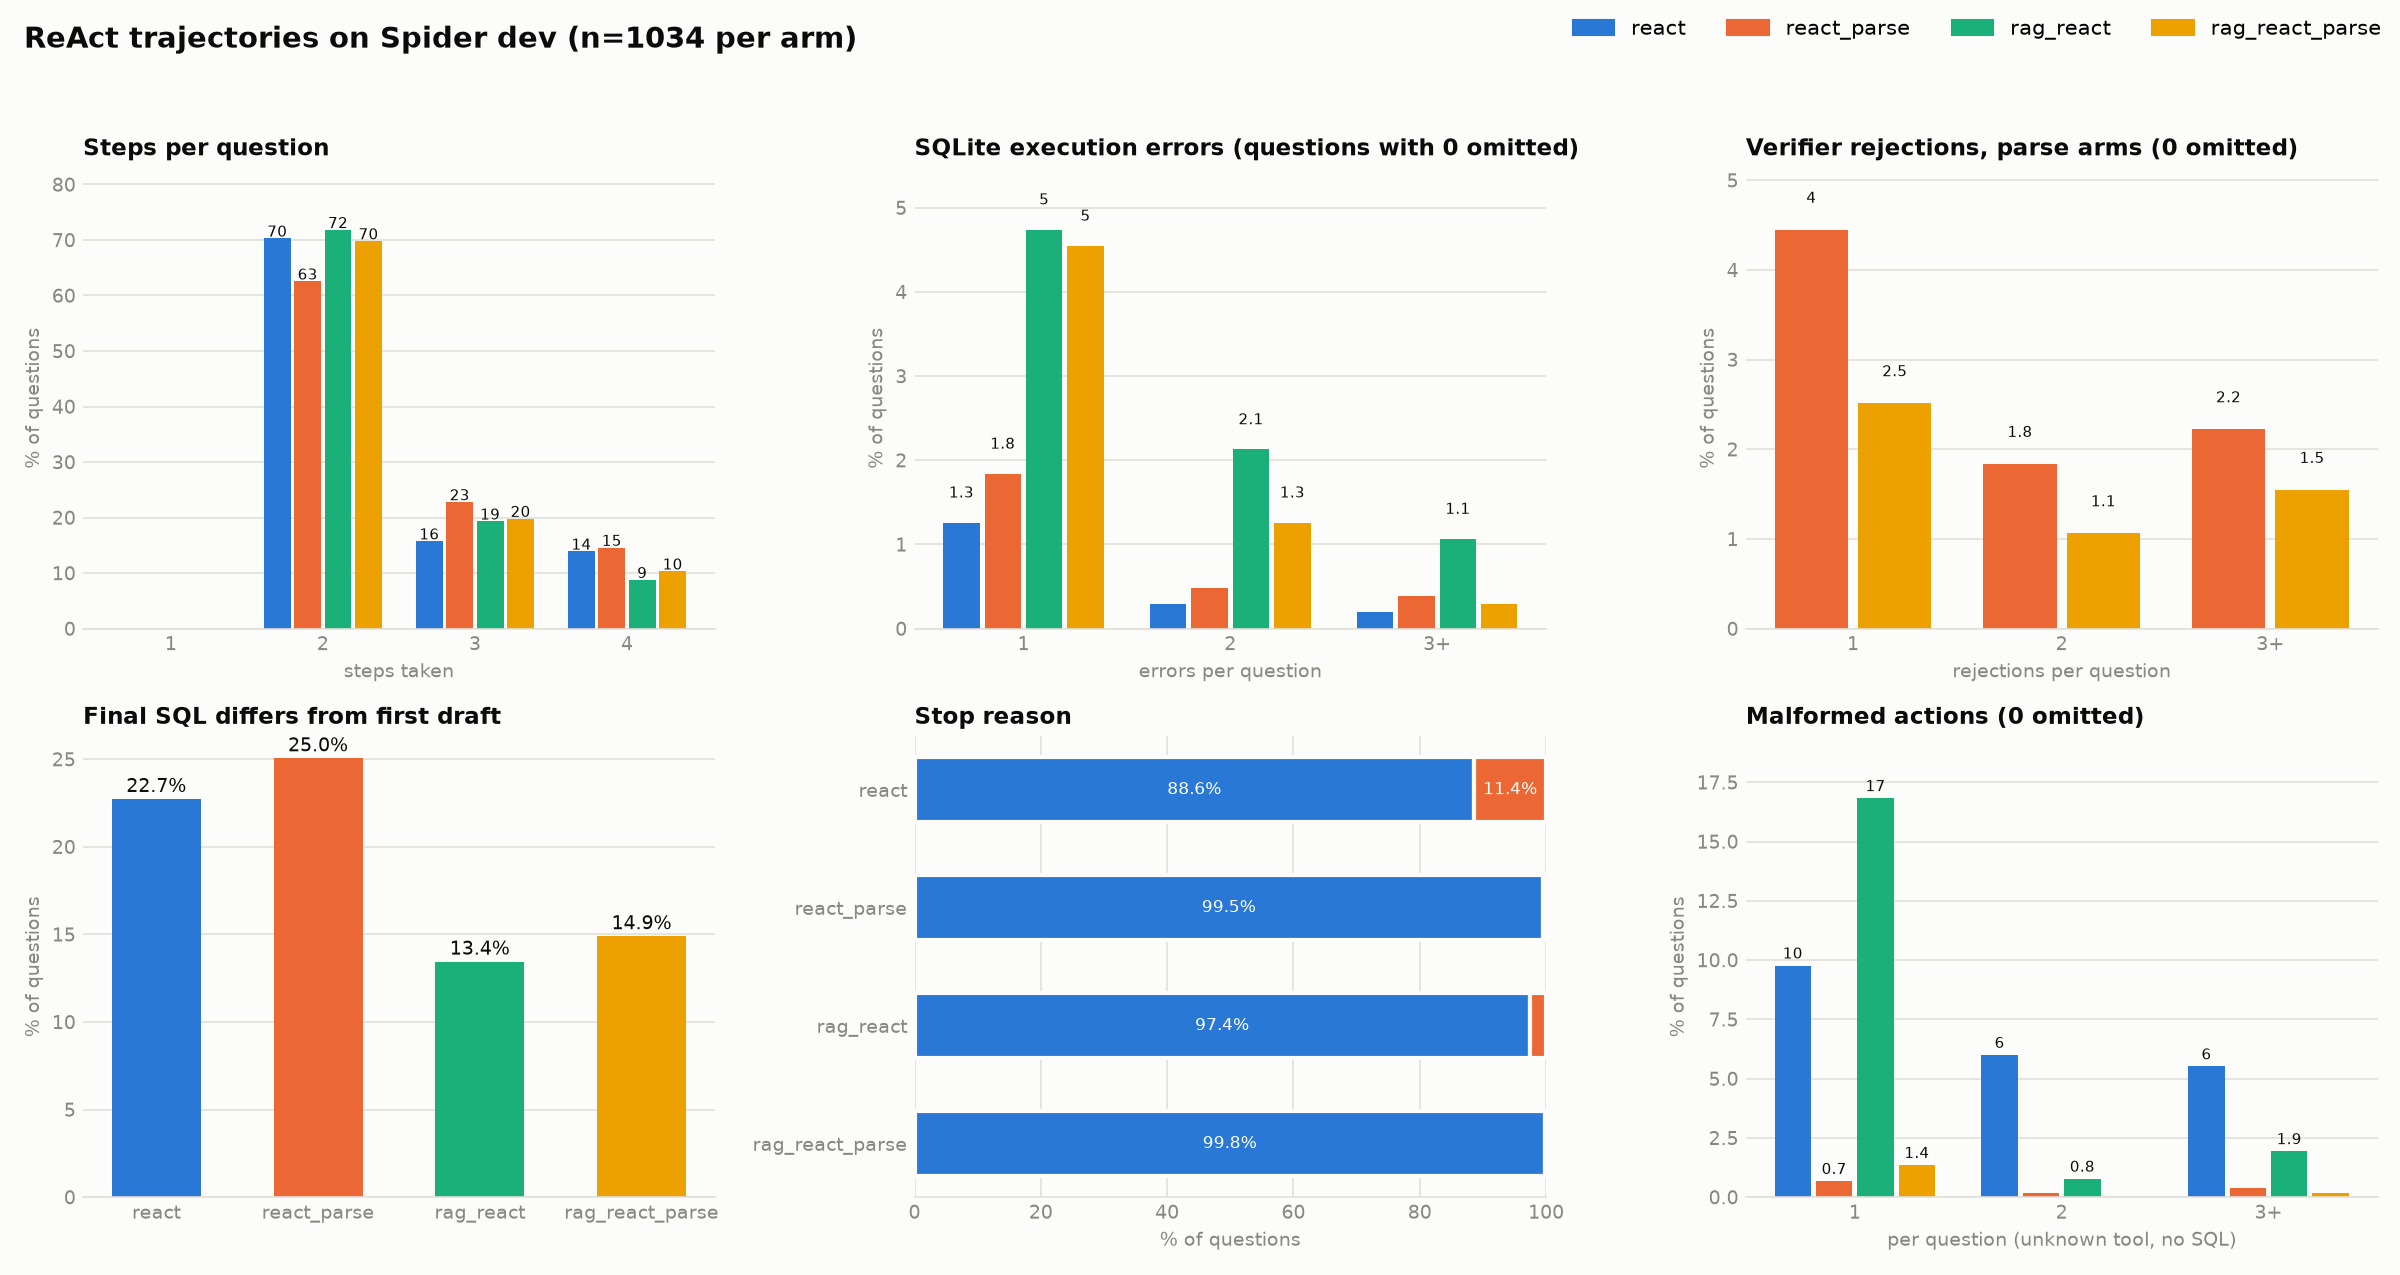

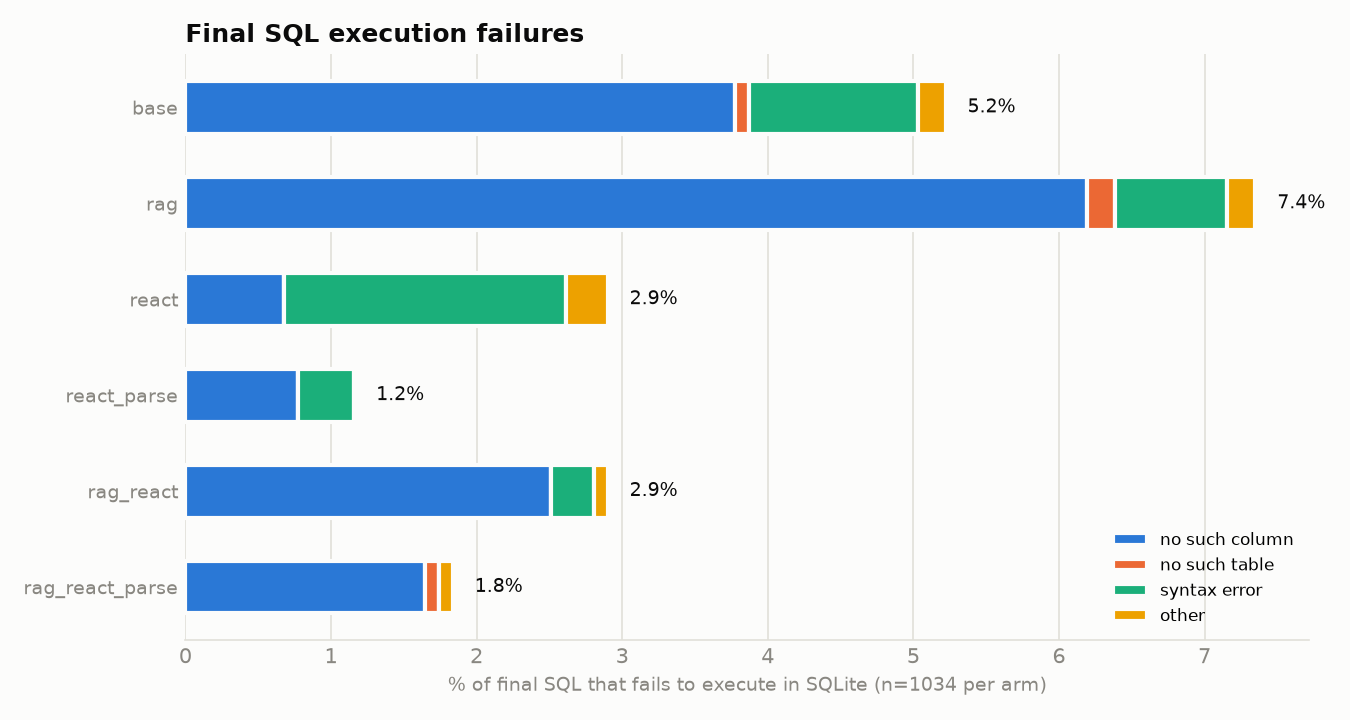

In [12]:
from IPython.display import Image
from agent_ext import plot_trajectories, final_exec

run_main(plot_trajectories.main, ["--run-id", RUN_ID])
run_main(final_exec.main, ["--run-id", RUN_ID])
FIGS = RESULTS_DIR / "figs"
for name in ["trajectories.png", "final_exec_errors.png"]:
    display(Image(filename=str(FIGS / name)))

## 6. Sampled traces

Each run saves `N_TRACES` random successes and failures to `agent_ext/results/<arm>/<RUN_ID>/traces/`, as `success.jsonl`, `failure.jsonl` and a readable `sample.md`. Pick an arm to view its sample.

To resample with a different size or seed without rerunning the model:

```bash
python -m agent_ext.traces agent_ext/results/<arm>/<RUN_ID> --n 10 --seed 1
```

In [13]:
ARM_TO_VIEW = "rag_react_parse"
display(Markdown((RESULTS_DIR / f"{ARM_TO_VIEW}/{RUN_ID}/traces/sample.md").read_text()))

# Sampled traces: rag_react_parse / repro
531 successes and 503 failures out of 1034 (Spider exact match); 5 sampled from each with seed 0.

## Success (5)

### dev #76 (pets_1, medium)
**Question:** What are the different first names and ages of the students who do have pets?

**Gold:** `SELECT DISTINCT T1.fname , T1.age FROM student AS T1 JOIN has_pet AS T2 ON T1.stuid = T2.stuid`

**Pred:** `SELECT DISTINCT Student.Fname, Student.Age FROM Student JOIN Has_Pet ON Student.StuID = Has_Pet.StuID`

Parses in Spider: True. Gold uses a set op: False; pred does: False.

<details><summary>Retrieved few-shot examples</summary>

- What are the first names of all students who are older than 20? → `SELECT fname FROM student WHERE age > 20`
- What are the first names of students, ordered by age from greatest to least? → `SELECT Fname FROM STUDENT ORDER BY Age DESC`
- What are the last names and ages of the students who are allergic to milk and cat? → `SELECT lname , age FROM Student WHERE StuID IN (SELECT StuID FROM Has_allergy WHERE Allergy = "Milk" INTERSECT SELECT StuID FROM Has_allergy WHERE Allergy = "Cat")`
- What are the first names of all the students? → `SELECT DISTINCT fname FROM student`
- What are the first names of all the students aged above 22? → `SELECT Fname FROM STUDENT WHERE Age > 22`

</details>

Steps: 2, finished: True

**Step 1**
````
Thought: I need to find the different first names and ages of students who have pets. This requires joining the Student table with the Has_Pet table on StuID and then selecting distinct Fname and Age from the result.
Action: execute[```sql
SELECT DISTINCT Student.Fname, Student.Age
FROM Student
JOIN Has_Pet ON Student.StuID = Has_Pet.StuID;
```]
````
> Observation: OK: columns [Fname, Age]; 0 result rows (all tables are empty: the database has the schema only)

**Step 2**
````
Thought: The database is empty, so there are no results. The query is correct, but there are no rows to return. I will submit the query as the final answer.
Action: finish[```sql
SELECT DISTINCT Student.Fname, Student.Age
FROM Student
JOIN Has_Pet ON Student.StuID = Has_Pet.StuID;
```]
````

### dev #528 (student_transcripts_tracking, easy)
**Question:** What are the names of the sections in reverse alphabetical order?

**Gold:** `SELECT section_name FROM Sections ORDER BY section_name DESC`

**Pred:** `SELECT section_name FROM Sections ORDER BY section_name DESC`

Parses in Spider: True. Gold uses a set op: False; pred does: False.

<details><summary>Retrieved few-shot examples</summary>

- What are the names of the regions in alphabetical order? → `SELECT region_name FROM region ORDER BY region_name`
- What are the names of the courses in alphabetical order? → `SELECT course_name FROM courses ORDER BY course_name`
- What are the names of all departments in alphabetical order? → `SELECT dept_name FROM department ORDER BY dept_name`
- List the names of courses in alphabetical order? → `SELECT course_name FROM courses ORDER BY course_name`
- What are the names of cities in ascending alphabetical order? → `SELECT Name FROM city ORDER BY Name ASC`

</details>

Steps: 2, finished: True

**Step 1**
````
Thought: I need to retrieve the names of the sections from the "Sections" table and order them in reverse alphabetical order. The correct SQL query would select the "section_name" column and use the ORDER BY clause with DESC.
Action: execute[```sql
SELECT section_name FROM Sections ORDER BY section_name DESC
```]
````
> Observation: OK: columns [section_name]; 0 result rows (all tables are empty: the database has the schema only)

**Step 2**
````
Thought: The query executed successfully, and the result columns are as expected. Since there are no rows in the database, the result is empty. The query is correct.
Action: finish[```sql
SELECT section_name FROM Sections ORDER BY section_name DESC
```]
````

### dev #752 (world_1, hard)
**Question:** What are the regions that use English or Dutch?

**Gold:** `SELECT DISTINCT T1.Region FROM country AS T1 JOIN countrylanguage AS T2 ON T1.Code = T2.CountryCode WHERE T2.Language = "English" OR T2.Language = "Dutch"`

**Pred:** `SELECT country.Region FROM country JOIN countrylanguage ON country.Code = countrylanguage.CountryCode WHERE countrylanguage.Language = 'English' OR countrylanguage.Language = 'Dutch'`

Parses in Spider: True. Gold uses a set op: False; pred does: False.

<details><summary>Retrieved few-shot examples</summary>

- What are the areas and counties for all appelations? → `SELECT Area , County FROM APPELLATIONS`
- What are the different region names, ordered by labels? → `SELECT DISTINCT region_name FROM region ORDER BY Label`
- What are the official native languages that contain the string "English". → `SELECT Official_native_language FROM country WHERE Official_native_language LIKE "%English%"`
- What are the official languages of the countries of players from Maryland or Duke college? → `SELECT T1.Official_native_language FROM country AS T1 JOIN match_season AS T2 ON T1.Country_id = T2.Country WHERE T2.College = "Maryland" OR T2.College = "Duke"`
- What are the languages that are used most often in songs? → `SELECT languages FROM song GROUP BY languages ORDER BY count(*) DESC LIMIT 1`

</details>

Steps: 3, finished: True

**Step 1**
````
Thought: I need to find the regions that use English or Dutch. This can be done by querying the "countrylanguage" table for entries where the "Language" is "English" or "Dutch", and then joining with the "country" table to get the "Region" from those countries.
Action: spider_parse[```sql
SELECT country.Region FROM country JOIN countrylanguage ON country.Code = countrylanguage.CountryCode WHERE countrylanguage.Language = 'English' OR countrylanguage.Language = 'Dutch'
```]
````
> Observation: PARSES: the grader can read this query

**Step 2**
````
Thought: The query is parsed successfully. Now I will execute it to get the regions that use English or Dutch.
Action: execute[```sql
SELECT country.Region FROM country JOIN countrylanguage ON country.Code = countrylanguage.CountryCode WHERE countrylanguage.Language = 'English' OR countrylanguage.Language = 'Dutch'
```]
````
> Observation: OK: columns [Region]; 0 result rows (all tables are empty: the database has the schema only)

**Step 3**
````
Thought: The database is empty, so there are no results. However, the query is correct. I will submit the query as the final answer.
Action: finish[```sql
SELECT country.Region FROM country JOIN countrylanguage ON country.Code = countrylanguage.CountryCode WHERE countrylanguage.Language = 'English' OR countrylanguage.Language = 'Dutch'
```]
````

### dev #831 (orchestra, easy)
**Question:** Return the average attendance across all shows.

**Gold:** `SELECT avg(Attendance) FROM SHOW`

**Pred:** `SELECT AVG(Attendance) FROM show`

Parses in Spider: True. Gold uses a set op: False; pred does: False.

<details><summary>Retrieved few-shot examples</summary>

- List the hosts of performances in ascending order of attendance. → `SELECT HOST FROM performance ORDER BY Attendance ASC`
- For each year, return the year and the average number of attendance at home games. → `SELECT YEAR , avg(attendance) FROM home_game GROUP BY YEAR;`
- what are the average and maximum attendances of all events? → `SELECT avg(Event_Attendance) , max(Event_Attendance) FROM event`
- What is the average number of attendees for performances? → `SELECT avg(Attendance) FROM performance`
- Show all artist names with an average exhibition attendance over 200. → `SELECT T3.name FROM exhibition_record AS T1 JOIN exhibition AS T2 ON T1.exhibition_id = T2.exhibition_id JOIN artist AS T3 ON T3.artist_id = T2.artist_id GROUP BY T3.artist_id HAVING avg(T1.attendance) > 200`

</details>

Steps: 2, finished: True

**Step 1**
````
Thought: I need to calculate the average attendance from the "show" table. The "Attendance" column in the "show" table contains the attendance numbers for each show. I can use the AVG() function to compute the average.
Action: execute[```sql
SELECT AVG(Attendance) FROM show;
```]
````
> Observation: OK: columns [AVG(Attendance)]; 1 result rows (all tables are empty: the database has the schema only)

**Step 2**
````
Thought: The query executed successfully, and the result is the average attendance across all shows. Since the database is empty, the result is not a real value, but the query is correct.
Action: finish[```sql
SELECT AVG(Attendance) FROM show;
```]
````

### dev #1017 (singer, medium)
**Question:** For each citizenship, what is the maximum net worth?

**Gold:** `SELECT Citizenship , max(Net_Worth_Millions) FROM singer GROUP BY Citizenship`

**Pred:** `SELECT Citizenship, MAX(Net_Worth_Millions) FROM singer GROUP BY Citizenship`

Parses in Spider: True. Gold uses a set op: False; pred does: False.

<details><summary>Retrieved few-shot examples</summary>

- What is the id of every employee who has at least a salary of  100000? → `SELECT eid FROM Employee WHERE salary > 100000`
- What is the id and name of the employee with the highest salary? → `SELECT eid , name FROM Employee ORDER BY salary DESC LIMIT 1`
- what is the salary and name of the employee who has the most number of aircraft certificates? → `SELECT T1.name , T1.salary FROM Employee AS T1 JOIN Certificate AS T2 ON T1.eid = T2.eid GROUP BY T1.eid ORDER BY count(*) DESC LIMIT 1`
- What is the salary and name of the employee who has the most number of certificates on aircrafts with distance more than 5000? → `SELECT T1.name FROM Employee AS T1 JOIN Certificate AS T2 ON T1.eid = T2.eid JOIN Aircraft AS T3 ON T3.aid = T2.aid WHERE T3.distance > 5000 GROUP BY T1.eid ORDER BY count(*) DESC LIMIT 1`
- What are the full names and salaries for any employees earning less than 6000? → `SELECT first_name , last_name , salary FROM employees WHERE salary < 6000`

</details>

Steps: 2, finished: True

**Step 1**
````
Thought: I need to find the maximum net worth for each citizenship from the singer table. I can achieve this by grouping the singers by their citizenship and then using the MAX() function on the Net_Worth_Millions column.
Action: execute[```sql
SELECT Citizenship, MAX(Net_Worth_Millions) FROM singer GROUP BY Citizenship;
```]
````
> Observation: OK: columns [Citizenship, MAX(Net_Worth_Millions)]; 0 result rows (all tables are empty: the database has the schema only)

**Step 2**
````
Thought: The database is empty, so there are no results to return. I will submit the query as the final answer.
Action: finish[```sql
SELECT Citizenship, MAX(Net_Worth_Millions) FROM singer GROUP BY Citizenship;
```]
````

## Failure (5)

### dev #410 (course_teach, hard)
**Question:** What are the names of the teachers whose courses have not been arranged?

**Gold:** `SELECT Name FROM teacher WHERE Teacher_id NOT IN (SELECT Teacher_id FROM course_arrange)`

**Pred:** `SELECT teacher.Name FROM teacher LEFT JOIN course_arrange ON teacher.Teacher_ID = course_arrange.Teacher_ID WHERE course_arrange.Course_ID IS NULL`

Parses in Spider: False. Gold uses a set op: False; pred does: False.

<details><summary>Retrieved few-shot examples</summary>

- What are the first names of all teachers who have taught a course and the corresponding descriptions? → `SELECT T2.emp_fname , T3.crs_description FROM CLASS AS T1 JOIN employee AS T2 ON T1.prof_num = T2.emp_num JOIN course AS T3 ON T1.crs_code = T3.crs_code`
- What are the first names of all professors not teaching any classes? → `SELECT emp_fname FROM employee WHERE emp_jobcode = 'PROF' EXCEPT SELECT T1.emp_fname FROM employee AS T1 JOIN CLASS AS T2 ON T1.emp_num = T2.prof_num`
- What are the first names of all teachers who have taught a course and the corresponding course codes? → `SELECT T2.emp_fname , T1.crs_code FROM CLASS AS T1 JOIN employee AS T2 ON T1.prof_num = T2.emp_num`
- Find the name of instructors who didn't teach any courses? → `SELECT name FROM instructor WHERE id NOT IN (SELECT id FROM teaches)`
- What are the first names of the professors who do not teach a class. → `SELECT emp_fname FROM employee WHERE emp_jobcode = 'PROF' EXCEPT SELECT T1.emp_fname FROM employee AS T1 JOIN CLASS AS T2 ON T1.emp_num = T2.prof_num`

</details>

Steps: 2, finished: True

**Step 1**
````
Thought: I need to find the names of teachers whose courses have not been arranged. This means their Course_IDs are not present in the course_arrange table. I can use a LEFT JOIN to identify teachers without corresponding entries in course_arrange.
Action: execute[```sql
SELECT teacher.Name
FROM teacher
LEFT JOIN course_arrange ON teacher.Teacher_ID = course_arrange.Teacher_ID
WHERE course_arrange.Course_ID IS NULL;
```]
````
> Observation: OK: columns [Name]; 0 result rows (all tables are empty: the database has the schema only)

**Step 2**
````
Thought: Since the database is empty, there are no teachers whose courses have not been arranged. The query correctly identifies this by returning 0 rows.
Action: finish[```sql
SELECT teacher.Name
FROM teacher
LEFT JOIN course_arrange ON teacher.Teacher_ID = course_arrange.Teacher_ID
WHERE course_arrange.Course_ID IS NULL;
```]
````

### dev #487 (wta_1, hard)
**Question:** Find the first name, country code and birth date of the winner who has the highest rank points in all matches.

**Gold:** `SELECT T1.first_name , T1.country_code , T1.birth_date FROM players AS T1 JOIN matches AS T2 ON T1.player_id = T2.winner_id ORDER BY T2.winner_rank_points DESC LIMIT 1`

**Pred:** `SELECT p.first_name, p.country_code, p.birth_date FROM players AS p JOIN rankings AS r ON p.player_id = r.player_id ORDER BY r.ranking_points DESC LIMIT 1`

Parses in Spider: True. Gold uses a set op: False; pred does: False.

<details><summary>Retrieved few-shot examples</summary>

- Find the name and id of the good with the highest average rank. → `SELECT T1.title , T1.i_id FROM item AS T1 JOIN review AS T2 ON T1.i_id = T2.i_id GROUP BY T2.i_id ORDER BY avg(T2.rank) DESC LIMIT 1`
- Find the first name, last name and id for the top three players won the most player awards. → `SELECT T1.name_first , T1.name_last , T1.player_id FROM player AS T1 JOIN player_award AS T2 ON T1.player_id = T2.player_id GROUP BY T1.player_id ORDER BY count(*) DESC LIMIT 3;`
- Find the number of matches in different competitions. → `SELECT count(*) , Competition FROM MATCH GROUP BY Competition`
- For each competition, count the number of matches. → `SELECT count(*) , Competition FROM MATCH GROUP BY Competition`
- List the names of players in ascending order of votes. → `SELECT Player_name FROM player ORDER BY Votes ASC`

</details>

Steps: 4, finished: True

**Step 1**
````
Thought: I need to find the winner with the highest rank points. I will start by identifying the winner with the highest rank points from the "matches" table.
Action: execute[```sql
SELECT winner_id, MAX(winner_rank_points) AS max_rank_points FROM matches GROUP BY winner_id ORDER BY max_rank_points DESC LIMIT 1;
```]
````
> Observation: OK: columns [winner_id, max_rank_points]; 0 result rows (all tables are empty: the database has the schema only)

**Step 2**
````
Thought: Since there are no results, I need to check if there are any winners in the "matches" table. If there are, I can proceed to find the player's details from the "players" table.
Action: execute[```sql
SELECT COUNT(*) FROM matches;
```]
````
> Observation: OK: columns [COUNT(*)]; 1 result rows (all tables are empty: the database has the schema only)

**Step 3**
````
Thought: The database is empty, so I need to adjust my approach. I will directly query the "players" table to find the player with the highest rank points from the "rankings" table.
Action: execute[```sql
SELECT p.first_name, p.country_code, p.birth_date
FROM players AS p
JOIN rankings AS r ON p.player_id = r.player_id
ORDER BY r.ranking_points DESC
LIMIT 1;
```]
````
> Observation: OK: columns [first_name, country_code, birth_date]; 0 result rows (all tables are empty: the database has the schema only)
> You have one step left: use finish.

**Step 4**
````
Thought: The database is empty, so I cannot retrieve any data. I will submit the query as my final answer.
Action: finish[```sql
SELECT p.first_name, p.country_code, p.birth_date
FROM players AS p
JOIN rankings AS r ON p.player_id = r.player_id
ORDER BY r.ranking_points DESC
LIMIT 1;
```]
````

### dev #839 (orchestra, medium)
**Question:** What is the name of the conductor who has worked the greatest number of years?

**Gold:** `SELECT Name FROM conductor ORDER BY Year_of_Work DESC LIMIT 1`

**Pred:** `SELECT "Conductor_ID", MAX("Year_of_Work") - MIN("Year_of_Work") AS "Years_of_Work" FROM "conductor" GROUP BY "Conductor_ID" ORDER BY "Years_of_Work" DESC LIMIT 1`

Parses in Spider: False. Gold uses a set op: False; pred does: False.

<details><summary>Retrieved few-shot examples</summary>

- What is the last name of the musician that have produced the most number of songs? → `SELECT T2.lastname FROM Performance AS T1 JOIN Band AS T2 ON T1.bandmate = T2.id JOIN Songs AS T3 ON T3.SongId = T1.SongId GROUP BY lastname ORDER BY count(*) DESC LIMIT 1`
- What is the last name of the musician that have produced the most songs? → `SELECT T2.lastname FROM Performance AS T1 JOIN Band AS T2 ON T1.bandmate = T2.id JOIN Songs AS T3 ON T3.SongId = T1.SongId GROUP BY lastname ORDER BY count(*) DESC LIMIT 1`
- What is the joined year of the pilot of the highest rank? → `SELECT Join_Year FROM pilot ORDER BY Rank ASC LIMIT 1`
- What is the starting year of the oldest technicians? → `SELECT Starting_Year FROM technician ORDER BY Age DESC LIMIT 1`
- What is the starting year for the oldest technician? → `SELECT Starting_Year FROM technician ORDER BY Age DESC LIMIT 1`

</details>

Steps: 4, finished: True

**Step 1**
````
Thought: I need to find the conductor with the greatest number of years of work. This requires calculating the difference between the maximum and minimum "Year_of_Work" for each conductor and then selecting the conductor with the largest difference.
Action: spider_parse```sql
SELECT "Conductor_ID", MAX("Year_of_Work") - MIN("Year_of_Work") AS "Years_of_Work" FROM "conductor" GROUP BY "Conductor_ID" ORDER BY "Years_of_Work" DESC LIMIT 1
```
````
> Observation: PARSE ERROR: the grader cannot read this query (KeyError: '"conductor"')

**Step 2**
````
Thought: The error indicates that the grader cannot parse the query. I need to adjust the query to use the correct table name and column names as per the database schema.
Action: spider_parse```sql
SELECT "Conductor_ID", MAX("Year_of_Work") - MIN("Year_of_Work") AS "Years_of_Work" FROM "conductor" GROUP BY "Conductor_ID" ORDER BY "Years_of_Work" DESC LIMIT 1
```
````
> Observation: PARSE ERROR: the grader cannot read this query (KeyError: '"conductor"')

**Step 3**
````
Thought: The error persists, indicating a problem with the query structure or table name. I need to ensure the query is correctly formatted and uses the correct table name.
Action: spider_parse```sql
SELECT "Conductor_ID", MAX("Year_of_Work") - MIN("Year_of_Work") AS "Years_of_Work" FROM "conductor" GROUP BY "Conductor_ID" ORDER BY "Years_of_Work" DESC LIMIT 1
```
````
> Observation: PARSE ERROR: the grader cannot read this query (KeyError: '"conductor"')
> You have one step left: use finish.

**Step 4**
````
Thought: The query is correct, but the grader is unable to parse it. I will submit the query as the final answer.
Action: finish```sql
SELECT "Conductor_ID", MAX("Year_of_Work") - MIN("Year_of_Work") AS "Years_of_Work" FROM "conductor" GROUP BY "Conductor_ID" ORDER BY "Years_of_Work" DESC LIMIT 1
```
````

### dev #883 (network_1, medium)
**Question:** How many friends does each student have?

**Gold:** `SELECT student_id , count(*) FROM Friend GROUP BY student_id`

**Pred:** `SELECT student_id, COUNT(friend_id) AS num_friends FROM Friend GROUP BY student_id`

Parses in Spider: False. Gold uses a set op: False; pred does: False.

<details><summary>Retrieved few-shot examples</summary>

- How many students are there? → `SELECT count(*) FROM list`
- How many students are there? → `SELECT count(*) FROM student`
- How many students are there? → `SELECT count(*) FROM student`
- How many students are there? → `SELECT count(*) FROM Student`
- How many students exist? → `SELECT count(*) FROM student`

</details>

Steps: 2, finished: True

**Step 1**
````
Thought: I need to count the number of friends each student has. The "Friend" table contains the "student_id" and "friend_id", so I can use this table to determine the number of friends each student has.
Action: execute[```sql
SELECT student_id, COUNT(friend_id) AS num_friends FROM Friend GROUP BY student_id;
```]
````
> Observation: OK: columns [student_id, num_friends]; 0 result rows (all tables are empty: the database has the schema only)

**Step 2**
````
Thought: The query executed successfully, but since the database is empty, there are no results. I need to confirm that the query is correct and submit it as the final answer.
Action: finish[```sql
SELECT student_id, COUNT(friend_id) AS num_friends FROM Friend GROUP BY student_id;
```]
````

### dev #937 (dog_kennels, extra)
**Question:** Tell me the owner id and last name of the owner who spent the most on treatments of his or her dogs.

**Gold:** `SELECT T1.owner_id , T1.last_name FROM Owners AS T1 JOIN Dogs AS T2 ON T1.owner_id = T2.owner_id JOIN Treatments AS T3 ON T2.dog_id = T3.dog_id GROUP BY T1.owner_id ORDER BY count(*) DESC LIMIT 1`

**Pred:** `SELECT Owners.owner_id, Owners.last_name, SUM(Treatments.cost_of_treatment) AS total_cost FROM Owners JOIN Dogs ON Owners.owner_id = Dogs.owner_id JOIN Treatments ON Dogs.dog_id = Treatments.dog_id GROUP BY Owners.owner_id, Owners.last_name ORDER BY total_cost DESC LIMIT 1`

Parses in Spider: False. Gold uses a set op: False; pred does: False.

<details><summary>Retrieved few-shot examples</summary>

- Which patients made more than one appointment? Tell me the name and phone number of these patients. → `SELECT name , phone FROM appointment AS T1 JOIN patient AS T2 ON T1.patient = T2.ssn GROUP BY T1.patient HAVING count(*) > 1`
- Find the physician who prescribed the highest dose. What is his or her name? → `SELECT T1.name FROM physician AS T1 JOIN prescribes AS T2 ON T1.employeeid = T2.physician ORDER BY T2.dose DESC LIMIT 1`
- Find the physician who was trained in the most expensive procedure? → `SELECT T1.name FROM physician AS T1 JOIN trained_in AS T2 ON T1.employeeid = T2.physician JOIN procedures AS T3 ON T3.code = T2.treatment ORDER BY T3.cost DESC LIMIT 1`
- Find the patient who has the most recent undergoing treatment? → `SELECT patient FROM undergoes ORDER BY dateundergoes LIMIT 1`
- What are the names of the physician who prescribed the highest dose? → `SELECT T1.name FROM physician AS T1 JOIN prescribes AS T2 ON T1.employeeid = T2.physician ORDER BY T2.dose DESC LIMIT 1`

</details>

Steps: 2, finished: True

**Step 1**
````
Thought: I need to calculate the total cost of treatments for each owner and find the owner with the highest total cost.
Action: execute[```sql
SELECT Owners.owner_id, Owners.last_name, SUM(Treatments.cost_of_treatment) AS total_cost
FROM Owners
JOIN Dogs ON Owners.owner_id = Dogs.owner_id
JOIN Treatments ON Dogs.dog_id = Treatments.dog_id
GROUP BY Owners.owner_id, Owners.last_name
ORDER BY total_cost DESC
LIMIT 1;
```]
````
> Observation: OK: columns [owner_id, last_name, total_cost]; 0 result rows (all tables are empty: the database has the schema only)

**Step 2**
````
Thought: The database is empty, so there are no results to return. I will submit the query as the final answer.
Action: finish[```sql
SELECT Owners.owner_id, Owners.last_name, SUM(Treatments.cost_of_treatment) AS total_cost
FROM Owners
JOIN Dogs ON Owners.owner_id = Dogs.owner_id
JOIN Treatments ON Dogs.dog_id = Treatments.dog_id
GROUP BY Owners.owner_id, Owners.last_name
ORDER BY total_cost DESC
LIMIT 1;
```]
````
